In [27]:
# SETUP & REPRODUCIBILITAS
import os, time, json, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [28]:
from pathlib import Path
import glob, shutil

CLASSES = ["Abyssinian", "Bengal", "Maine_Coon", "Persian", "Siamese",
           "beagle", "boxer", "german_shorthaired", "samoyed", "pug"]

base = Path("./data/oxford-iiit-pet")
datasets.OxfordIIITPet(root="./data", split="trainval", download=True)
if not (base / "images").exists():
    shutil.rmtree(base, ignore_errors=True)
    datasets.OxfordIIITPet(root="./data", split="trainval", download=True)
print("n jpg total:", len(glob.glob(str(base / "images" / "*.jpg"))))

pool_paths, pool_labels = [], []
for p in sorted(glob.glob(str(base / "images" / "*.jpg"))):
    name = Path(p).name.rsplit("_", 1)[0]
    if name in CLASSES:
        pool_paths.append(p)
        pool_labels.append(CLASSES.index(name))

idx = np.arange(len(pool_paths))
idx_tr, idx_tmp, y_tr, y_tmp = train_test_split(idx, pool_labels, test_size=0.30,
                                                stratify=pool_labels, random_state=SEED)
idx_va, idx_te, _, _ = train_test_split(idx_tmp, y_tmp, test_size=0.50,
                                        stratify=y_tmp, random_state=SEED)
print(f"Pool: {len(pool_paths)} | Train: {len(idx_tr)} | Val: {len(idx_va)} | Test: {len(idx_te)}")

n jpg total: 7390
Pool: 2000 | Train: 1400 | Val: 300 | Test: 300


In [29]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

def make_train_transforms(aug=True):
    if aug:
        return transforms.Compose([
            transforms.Resize(256),
            transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.ToTensor(),
            transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
        ])
    return transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
    ])

eval_transforms = weights.transforms()

class PetSubset(Dataset):
    def __init__(self, indices, transform):
        self.paths  = [pool_paths[i] for i in indices]
        self.labels = [pool_labels[i] for i in indices]
        self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

def make_loaders(aug=True, batch_size=32):
    tr = DataLoader(PetSubset(idx_tr, make_train_transforms(aug)), batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    va = DataLoader(PetSubset(idx_va, eval_transforms), batch_size, shuffle=False, num_workers=2, pin_memory=True)
    te = DataLoader(PetSubset(idx_te, eval_transforms), batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return tr, va, te

In [30]:
def build_model(mode):
    if mode == "scratch":
        m = models.resnet18(weights=None)
    else:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        if mode in ("feature_extraction", "fine_tune"):
            for param in m.parameters():
                param.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, 10)
    if mode == "fine_tune":
        for param in m.layer4.parameters():
            param.requires_grad = True
    return m

def build_optimizer(model, mode):
    if mode == "fine_tune":
        return torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(),     "lr": 1e-3},
        ], weight_decay=1e-2)
    return torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                             lr=1e-3, weight_decay=1e-2)

for mode in ["scratch", "feature_extraction", "fine_tune"]:
    m = build_model(mode)
    tp = sum(p.numel() for p in m.parameters() if p.requires_grad)
    tt = sum(p.numel() for p in m.parameters())
    print(f"{mode:20s} trainable: {tp:>10,} / total: {tt:,}")
    del m

scratch              trainable: 11,181,642 / total: 11,181,642
feature_extraction   trainable:      5,130 / total: 11,181,642
fine_tune            trainable:  8,398,858 / total: 11,181,642


In [31]:
import copy, csv

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return loss_sum / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    preds, trues = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        loss = criterion(out, y)
        loss_sum += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
        preds.extend(out.argmax(1).cpu().numpy()); trues.extend(y.cpu().numpy())
    return loss_sum / n, correct / n, preds, trues

In [32]:
ALL_SUMMARIES = []

def run_experiment(name, mode, aug=True, patience=4, max_epochs=30):
    set_seed(SEED)
    tr, va, te = make_loaders(aug=aug)
    model = build_model(mode).to(device)
    optimizer = build_optimizer(model, mode)
    criterion = nn.CrossEntropyLoss()

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    lr_groups = [g["lr"] for g in optimizer.param_groups]

    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "train_acc": []}
    best_loss, best_acc, best_state, best_epoch, wait = float("inf"), 0.0, None, 0, 0
    t0 = time.time()

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, tr, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, va, criterion)
        history["epoch"].append(epoch); history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss); history["val_acc"].append(va_acc); history["train_acc"].append(tr_acc)
        print(f"[{name}] Ep {epoch:02d} | tr_loss {tr_loss:.4f} | va_loss {va_loss:.4f} | va_acc {va_acc:.4f}")

        if va_loss < best_loss - 1e-6:
            best_loss, best_acc, best_epoch, wait = va_loss, va_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                print(f"[{name}] Early stopping di epoch {epoch} (best: {best_epoch})")
                break

    duration = time.time() - t0
    model.load_state_dict(best_state)
    te_loss, te_acc, preds, trues = evaluate(model, te, criterion)
    f1 = f1_score(trues, preds, average="macro")

    summary = {"experiment": name, "mode": mode, "augmentation": aug,
               "trainable_params": trainable, "lr_groups": lr_groups,
               "epochs_run": epoch, "epoch_converged": best_epoch,
               "duration_sec": round(duration, 1),
               "val_acc_best": round(best_acc, 4),
               "test_acc": round(te_acc, 4), "test_macro_f1": round(f1, 4)}
    ALL_SUMMARIES.append(summary)

    os.makedirs("logs", exist_ok=True)
    with open(f"logs/{name}_history.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["epoch", "train_loss", "val_loss", "val_acc"])
        for i in range(len(history["epoch"])):
            w.writerow([history["epoch"][i], round(history["train_loss"][i], 5),
                        round(history["val_loss"][i], 5), round(history["val_acc"][i], 5)])
    with open(f"logs/{name}_summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    torch.save(best_state, f"logs/{name}_best.pth")
    print(f"[{name}] TEST -> acc: {te_acc:.4f} | macro-F1: {f1:.4f} | durasi: {duration/60:.1f} mnt")
    return summary, history

In [33]:
s_b1, h_b1 = run_experiment("B1_scratch", mode="scratch", aug=True, patience=4)

[B1_scratch] Ep 01 | tr_loss 2.3894 | va_loss 2.7102 | va_acc 0.1733
[B1_scratch] Ep 02 | tr_loss 2.1012 | va_loss 2.3281 | va_acc 0.1667
[B1_scratch] Ep 03 | tr_loss 1.9610 | va_loss 2.1494 | va_acc 0.2467
[B1_scratch] Ep 04 | tr_loss 1.8803 | va_loss 2.1760 | va_acc 0.2400
[B1_scratch] Ep 05 | tr_loss 1.8073 | va_loss 2.1864 | va_acc 0.3000
[B1_scratch] Ep 06 | tr_loss 1.7513 | va_loss 1.9522 | va_acc 0.3067
[B1_scratch] Ep 07 | tr_loss 1.6600 | va_loss 1.9922 | va_acc 0.3333
[B1_scratch] Ep 08 | tr_loss 1.5904 | va_loss 1.9449 | va_acc 0.3367
[B1_scratch] Ep 09 | tr_loss 1.5780 | va_loss 1.8721 | va_acc 0.3167
[B1_scratch] Ep 10 | tr_loss 1.5120 | va_loss 1.8623 | va_acc 0.3800
[B1_scratch] Ep 11 | tr_loss 1.4182 | va_loss 1.8945 | va_acc 0.3900
[B1_scratch] Ep 12 | tr_loss 1.3232 | va_loss 2.4138 | va_acc 0.3133
[B1_scratch] Ep 13 | tr_loss 1.3027 | va_loss 1.6834 | va_acc 0.4467
[B1_scratch] Ep 14 | tr_loss 1.3048 | va_loss 2.3282 | va_acc 0.3733
[B1_scratch] Ep 15 | tr_loss 1.220

In [34]:
s_b2, h_b2 = run_experiment("B2_feature_extraction", mode="feature_extraction", aug=True, patience=4)

[B2_feature_extraction] Ep 01 | tr_loss 1.2863 | va_loss 0.5522 | va_acc 0.9200
[B2_feature_extraction] Ep 02 | tr_loss 0.5537 | va_loss 0.3504 | va_acc 0.9267
[B2_feature_extraction] Ep 03 | tr_loss 0.4128 | va_loss 0.2563 | va_acc 0.9433
[B2_feature_extraction] Ep 04 | tr_loss 0.3245 | va_loss 0.2093 | va_acc 0.9533
[B2_feature_extraction] Ep 05 | tr_loss 0.2906 | va_loss 0.1897 | va_acc 0.9533
[B2_feature_extraction] Ep 06 | tr_loss 0.2649 | va_loss 0.1712 | va_acc 0.9600
[B2_feature_extraction] Ep 07 | tr_loss 0.2382 | va_loss 0.1654 | va_acc 0.9533
[B2_feature_extraction] Ep 08 | tr_loss 0.2242 | va_loss 0.1606 | va_acc 0.9500
[B2_feature_extraction] Ep 09 | tr_loss 0.2074 | va_loss 0.1418 | va_acc 0.9567
[B2_feature_extraction] Ep 10 | tr_loss 0.1950 | va_loss 0.1386 | va_acc 0.9667
[B2_feature_extraction] Ep 11 | tr_loss 0.1685 | va_loss 0.1330 | va_acc 0.9667
[B2_feature_extraction] Ep 12 | tr_loss 0.1752 | va_loss 0.1495 | va_acc 0.9533
[B2_feature_extraction] Ep 13 | tr_loss 

In [35]:
s_b3, h_b3 = run_experiment("B3_fine_tuning", mode="fine_tune", aug=True, patience=4)

[B3_fine_tuning] Ep 01 | tr_loss 0.6599 | va_loss 0.1578 | va_acc 0.9700
[B3_fine_tuning] Ep 02 | tr_loss 0.1671 | va_loss 0.1616 | va_acc 0.9600
[B3_fine_tuning] Ep 03 | tr_loss 0.1084 | va_loss 0.1580 | va_acc 0.9500
[B3_fine_tuning] Ep 04 | tr_loss 0.0622 | va_loss 0.1560 | va_acc 0.9400
[B3_fine_tuning] Ep 05 | tr_loss 0.0440 | va_loss 0.1598 | va_acc 0.9600
[B3_fine_tuning] Ep 06 | tr_loss 0.0339 | va_loss 0.1335 | va_acc 0.9600
[B3_fine_tuning] Ep 07 | tr_loss 0.0256 | va_loss 0.1506 | va_acc 0.9533
[B3_fine_tuning] Ep 08 | tr_loss 0.0220 | va_loss 0.1559 | va_acc 0.9533
[B3_fine_tuning] Ep 09 | tr_loss 0.0165 | va_loss 0.1348 | va_acc 0.9533
[B3_fine_tuning] Ep 10 | tr_loss 0.0106 | va_loss 0.1417 | va_acc 0.9667
[B3_fine_tuning] Early stopping di epoch 10 (best: 6)
[B3_fine_tuning] TEST -> acc: 0.9633 | macro-F1: 0.9635 | durasi: 2.6 mnt


In [36]:
s_b4, h_b4 = run_experiment("B4_no_aug", mode="feature_extraction", aug=False, patience=4)

[B4_no_aug] Ep 01 | tr_loss 1.1634 | va_loss 0.5077 | va_acc 0.9200
[B4_no_aug] Ep 02 | tr_loss 0.4514 | va_loss 0.3281 | va_acc 0.9400
[B4_no_aug] Ep 03 | tr_loss 0.3199 | va_loss 0.2565 | va_acc 0.9400
[B4_no_aug] Ep 04 | tr_loss 0.2571 | va_loss 0.2058 | va_acc 0.9600
[B4_no_aug] Ep 05 | tr_loss 0.2141 | va_loss 0.1929 | va_acc 0.9467
[B4_no_aug] Ep 06 | tr_loss 0.1890 | va_loss 0.1657 | va_acc 0.9567
[B4_no_aug] Ep 07 | tr_loss 0.1673 | va_loss 0.1660 | va_acc 0.9467
[B4_no_aug] Ep 08 | tr_loss 0.1451 | va_loss 0.1517 | va_acc 0.9633
[B4_no_aug] Ep 09 | tr_loss 0.1344 | va_loss 0.1423 | va_acc 0.9567
[B4_no_aug] Ep 10 | tr_loss 0.1207 | va_loss 0.1351 | va_acc 0.9567
[B4_no_aug] Ep 11 | tr_loss 0.1131 | va_loss 0.1258 | va_acc 0.9633
[B4_no_aug] Ep 12 | tr_loss 0.1051 | va_loss 0.1295 | va_acc 0.9600
[B4_no_aug] Ep 13 | tr_loss 0.1017 | va_loss 0.1221 | va_acc 0.9633
[B4_no_aug] Ep 14 | tr_loss 0.0989 | va_loss 0.1256 | va_acc 0.9667
[B4_no_aug] Ep 15 | tr_loss 0.0921 | va_loss 0.1

In [ ]:
import pandas as pd
df = pd.DataFrame(ALL_SUMMARIES)
df.to_csv("logs/consolidated_results.csv", index=False)
df

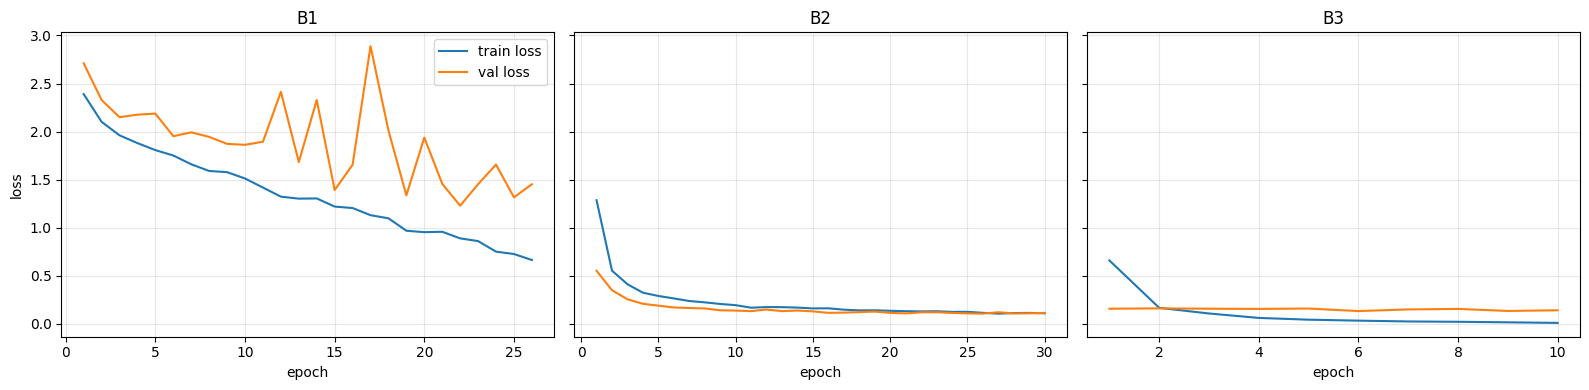

In [38]:
pairs = [("B1", h_b1), ("B2", h_b2), ("B3", h_b3)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, h) in zip(axes, pairs):
    ax.plot(h["epoch"], h["train_loss"], label="train loss")
    ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("loss")
axes[0].legend()
plt.tight_layout()
plt.show()

In [39]:
for name, h, s in [("B1", h_b1, s_b1), ("B2", h_b2, s_b2), ("B3", h_b3, s_b3), ("B4_no_aug", h_b4, s_b4)]:
    i = s["epoch_converged"] - 1
    gap = h["train_acc"][i] - h["val_acc"][i]
    print(f"{name:12s} train_acc {h['train_acc'][i]:.4f} | val_acc {h['val_acc'][i]:.4f} | gap {gap:+.4f}")

B1           train_acc 0.6864 | val_acc 0.5867 | gap +0.0998
B2           train_acc 0.9693 | val_acc 0.9700 | gap -0.0007
B3           train_acc 0.9914 | val_acc 0.9600 | gap +0.0314
B4_no_aug    train_acc 0.9900 | val_acc 0.9733 | gap +0.0167


salah: 12 dari 300
true: boxer                pred: pug                  conf: 0.8785
true: Maine_Coon           pred: Persian              conf: 0.7889
true: Maine_Coon           pred: Bengal               conf: 0.6663
true: Bengal               pred: Maine_Coon           conf: 0.6411
true: Siamese              pred: Maine_Coon           conf: 0.4954
true: beagle               pred: Abyssinian           conf: 0.6637
true: Maine_Coon           pred: Bengal               conf: 0.9666
true: pug                  pred: boxer                conf: 0.9392
true: Maine_Coon           pred: Bengal               conf: 0.7566
true: Persian              pred: Maine_Coon           conf: 0.6357
true: Maine_Coon           pred: Persian              conf: 0.5753
true: Persian              pred: Maine_Coon           conf: 0.5196


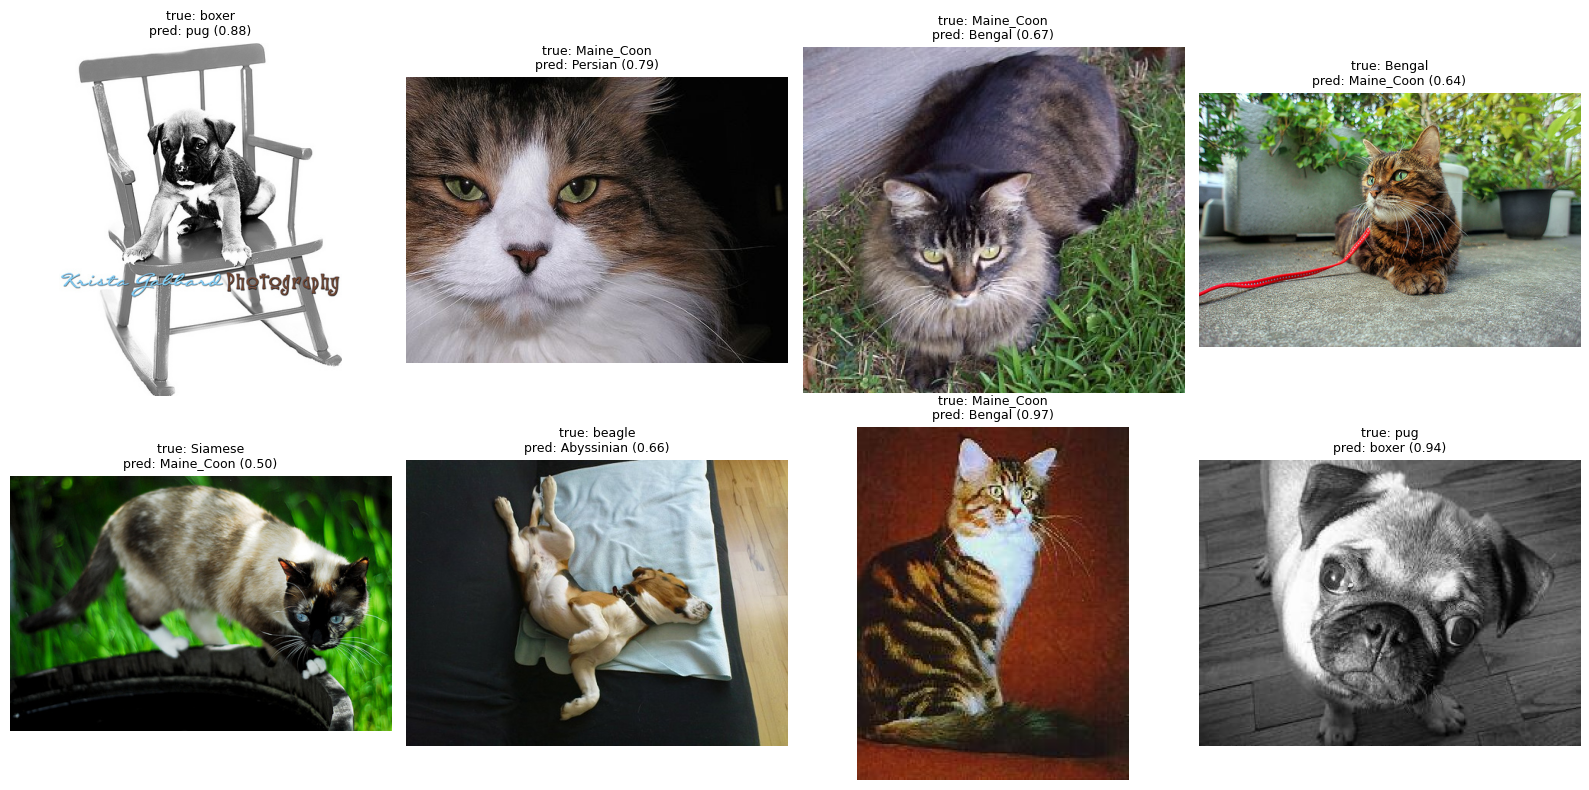

In [40]:
def load_best(name, mode):
    m = build_model(mode).to(device)
    m.load_state_dict(torch.load(f"logs/{name}_best.pth", map_location=device, weights_only=True))
    return m

best_model = load_best("B2_feature_extraction", "feature_extraction")
_, _, te = make_loaders(aug=False)
best_model.eval()
probs_l, preds_l, trues_l = [], [], []
with torch.no_grad():
    for x, y in te:
        x = x.to(device, non_blocking=True)
        p = torch.softmax(best_model(x), 1)
        probs_l.append(p.cpu()); preds_l.append(p.argmax(1).cpu()); trues_l.append(y)
probs_all = torch.cat(probs_l)
preds_all = torch.cat(preds_l).numpy()
trues_all = torch.cat(trues_l).numpy()
wrong_idx = np.where(preds_all != trues_all)[0]
print("salah:", len(wrong_idx), "dari", len(trues_all))

for i in wrong_idx:
    print(f"true: {CLASSES[trues_all[i]]:20s} pred: {CLASSES[preds_all[i]]:20s} conf: {probs_all[i][preds_all[i]]:.4f}")

n_show = min(len(wrong_idx), 8)
cols = 4
rows = max(1, int(np.ceil(n_show / cols)))
te_ds = te.dataset
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = np.array(axes).ravel()
for ax, i in zip(axes, wrong_idx[:n_show]):
    img = Image.open(te_ds.paths[i]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"true: {CLASSES[trues_all[i]]}\npred: {CLASSES[preds_all[i]]} ({probs_all[i][preds_all[i]]:.2f})", fontsize=9)
    ax.axis("off")
for ax in axes[n_show:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("logs/failure_analysis.png", dpi=150, bbox_inches="tight")
plt.show()